In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ttt=pd.read_csv('tic_tac_toe.txt', header=None)
print(ttt.shape)
ttt.head()

(958, 10)


,0,1,2,3,4,5,6,7,8,9
0,x,x,x,x,o,o,x,o,o,positive
1,x,x,x,x,o,o,o,x,o,positive
2,x,x,x,x,o,o,o,o,x,positive
3,x,x,x,x,o,o,o,b,b,positive
4,x,x,x,x,o,o,b,o,b,positive


In [107]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score

X = OrdinalEncoder().fit_transform(ttt.iloc[:, :9])  # признаки: x/o/b -> числа
y = ttt[9]                                           # класс: positive/negative

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

model = CategoricalNB()
model.fit(X_train, y_train)
print('train:', accuracy_score(y_train, model.predict(X_train)))
print('test :', accuracy_score(y_test, model.predict(X_test)))

train: 0.7134328358208956
test : 0.6875


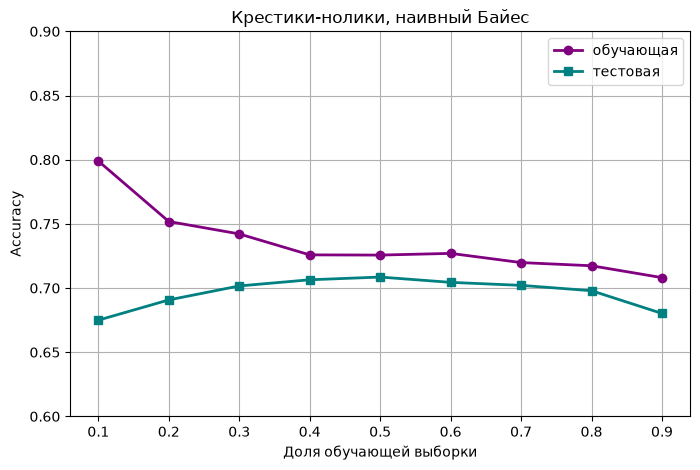

In [108]:
ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
train_acc, test_acc = [], []

for r in ratios:
    tr, te = [], []
    for seed in range(10):   # 10 разных случайных разбиений
        X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=r, random_state=seed)
        model = CategoricalNB(min_categories=3).fit(X_train, y_train)
        tr.append(accuracy_score(y_train, model.predict(X_train)))
        te.append(accuracy_score(y_test, model.predict(X_test)))
    train_acc.append(np.mean(tr))
    test_acc.append(np.mean(te))

plt.figure(figsize=(8, 5))
plt.plot(ratios, train_acc, marker='o', color='purple', linewidth=2, label='обучающая')
plt.plot(ratios, test_acc, marker='s', color='teal', linewidth=2, label='тестовая')
plt.xlabel('Доля обучающей выборки')
plt.ylabel('Accuracy')
plt.title('Крестики-нолики, наивный Байес')
plt.legend()
plt.grid(True)
plt.ylim(0.6, 0.9)
plt.show()

In [109]:
pd.DataFrame({'Доля train': ratios,
              'Accuracy train': train_acc,
              'Accuracy test': test_acc}).round(3)

,Доля train,Accuracy train,Accuracy test
0,0.1,0.799,0.675
1,0.2,0.752,0.691
2,0.3,0.742,0.702
3,0.4,0.726,0.706
4,0.5,0.726,0.709
5,0.6,0.727,0.704
6,0.7,0.720,0.702
7,0.8,0.717,0.698
8,0.9,0.708,0.680


In [110]:
from sklearn.naive_bayes import GaussianNB

spam = pd.read_csv('spam.csv')
print(spam.shape)
X_s = spam.drop(columns=[spam.columns[0], 'type'])  # признаки
y_s = spam['type']                                   # класс: spam / nonspam
print(y_s.value_counts())

(4601, 59)
type
nonspam    2788
spam       1813
Name: count, dtype: int64


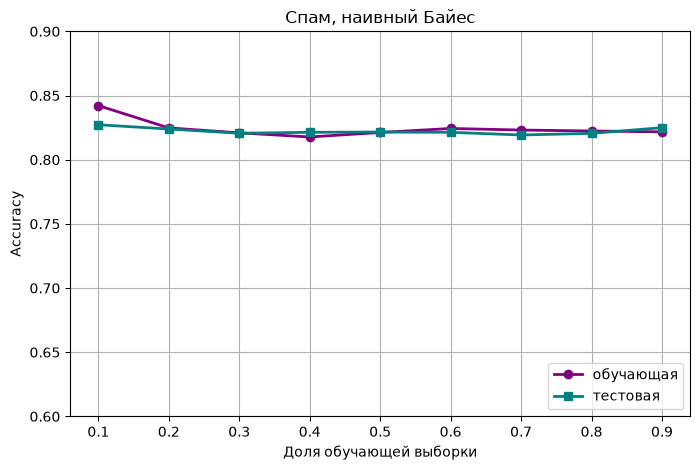

In [111]:
ratios = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
train_acc_s, test_acc_s = [], []

for r in ratios:
    tr, te = [], []
    for seed in range(10):   # 10 разных случайных разбиений
        X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, train_size=r, random_state=seed)
        model = GaussianNB().fit(X_train, y_train)
        tr.append(accuracy_score(y_train, model.predict(X_train)))
        te.append(accuracy_score(y_test, model.predict(X_test)))
    train_acc_s.append(np.mean(tr))
    test_acc_s.append(np.mean(te))

plt.figure(figsize=(8, 5))
plt.plot(ratios, train_acc_s, marker='o', color='purple', linewidth=2, label='обучающая')
plt.plot(ratios, test_acc_s, marker='s', color='teal', linewidth=2, label='тестовая')
plt.xlabel('Доля обучающей выборки')
plt.ylabel('Accuracy')
plt.title('Спам, наивный Байес')
plt.legend(loc='lower right')
plt.grid(True)
plt.ylim(0.6, 0.9)
plt.show()

In [112]:
pd.DataFrame({'Доля train': ratios,
              'Accuracy train': train_acc_s,
              'Accuracy test': test_acc_s}).round(3)

,Доля train,Accuracy train,Accuracy test
0,0.1,0.842,0.827
1,0.2,0.825,0.824
2,0.3,0.821,0.821
3,0.4,0.818,0.821
4,0.5,0.821,0.822
5,0.6,0.824,0.821
6,0.7,0.823,0.819
7,0.8,0.822,0.821
8,0.9,0.822,0.825


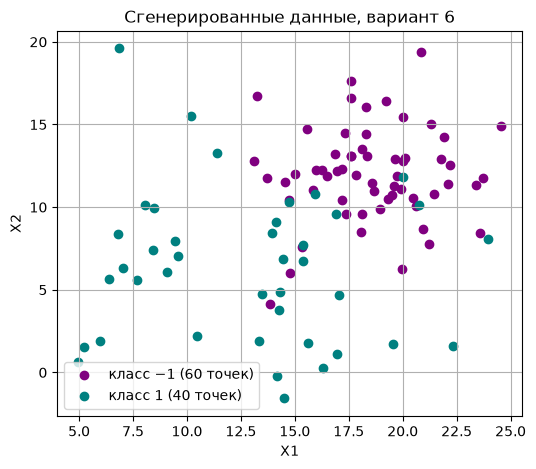

In [113]:
np.random.seed(42)
n_neg, n_pos = 60, 40

# класс −1: мат. ожидание X1 = 19, X2 = 12, СКО = 3
X_neg = np.column_stack([np.random.normal(19, 3, n_neg), np.random.normal(12, 3, n_neg)])
# класс 1: мат. ожидание X1 = 13, X2 = 6, СКО = 5
X_pos = np.column_stack([np.random.normal(13, 5, n_pos), np.random.normal(6, 5, n_pos)])

X2 = np.vstack([X_neg, X_pos])
y2 = np.array([-1] * n_neg + [1] * n_pos)

plt.figure(figsize=(6, 5))
plt.scatter(X_neg[:, 0], X_neg[:, 1], color='purple', label='класс −1 (60 точек)')
plt.scatter(X_pos[:, 0], X_pos[:, 1], color='teal', label='класс 1 (40 точек)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Сгенерированные данные, вариант 6')
plt.legend()
plt.grid(True)
plt.show()

accuracy train: 0.9285714285714286
accuracy test : 0.8666666666666667
[[16  2]
 [ 2 10]]


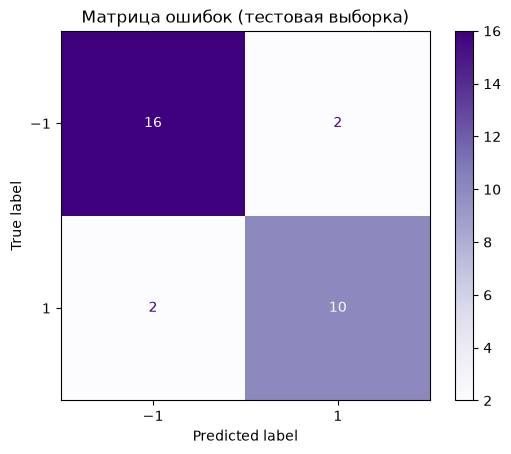

In [114]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.3, random_state=42, stratify=y2)

nb = GaussianNB().fit(X2_train, y2_train)
y2_pred = nb.predict(X2_test)

print('accuracy train:', accuracy_score(y2_train, nb.predict(X2_train)))
print('accuracy test :', accuracy_score(y2_test, y2_pred))

cm = confusion_matrix(y2_test, y2_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=['−1', '1']).plot(cmap='Purples')
plt.title('Матрица ошибок (тестовая выборка)')
plt.show()

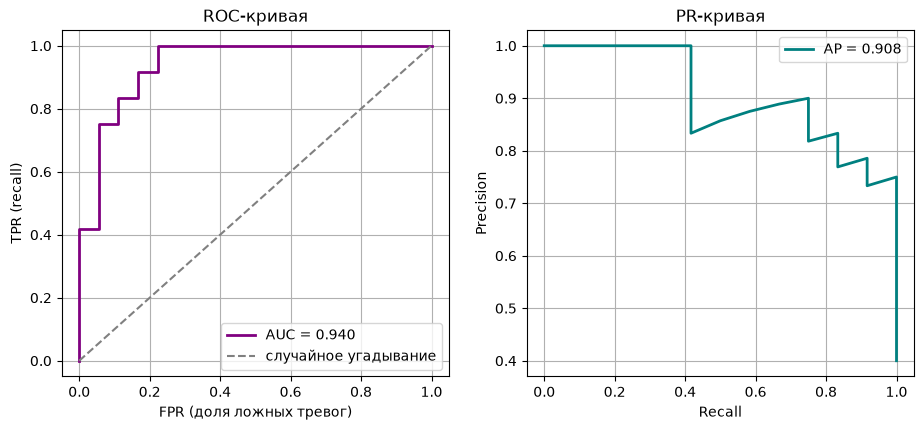

In [115]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

proba = nb.predict_proba(X2_test)[:, 1]   # вероятность класса 1 для каждой точки

fpr, tpr, _ = roc_curve(y2_test, proba)
prec, rec, _ = precision_recall_curve(y2_test, proba)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(fpr, tpr, color='purple', linewidth=2, label=f'AUC = {roc_auc_score(y2_test, proba):.3f}')
ax[0].plot([0, 1], [0, 1], '--', color='gray', label='случайное угадывание')
ax[0].set_xlabel('FPR (доля ложных тревог)')
ax[0].set_ylabel('TPR (recall)')
ax[0].set_title('ROC-кривая')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(rec, prec, color='teal', linewidth=2, label=f'AP = {average_precision_score(y2_test, proba):.3f}')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('PR-кривая')
ax[1].legend()
ax[1].grid(True)
plt.show()

In [116]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

glass = pd.read_csv('glass.csv')
print(glass.shape)
print(glass['Type'].value_counts().sort_index())

X3 = glass.drop(columns=['Id', 'Type'])   # Id — просто номер, убираем по заданию
y3 = glass['Type']

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.3, random_state=42, stratify=y3)

scaler = StandardScaler().fit(X3_train)   # считаем среднее и СКО на обучающей
X3_train_s = scaler.transform(X3_train)
X3_test_s = scaler.transform(X3_test)

(214, 11)
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


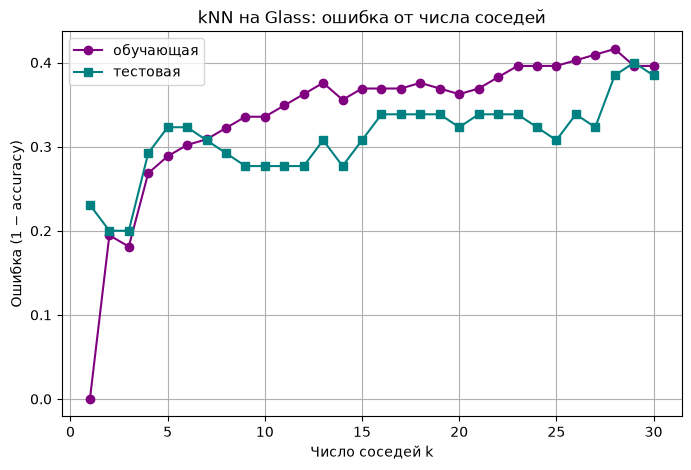

In [117]:
ks = range(1, 31)
err_train, err_test = [], []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X3_train_s, y3_train)
    err_train.append(1 - knn.score(X3_train_s, y3_train))
    err_test.append(1 - knn.score(X3_test_s, y3_test))

plt.figure(figsize=(8, 5))
plt.plot(ks, err_train, marker='o', color='purple', label='обучающая')
plt.plot(ks, err_test, marker='s', color='teal', label='тестовая')
plt.xlabel('Число соседей k')
plt.ylabel('Ошибка (1 − accuracy)')
plt.title('kNN на Glass: ошибка от числа соседей')
plt.legend()
plt.grid(True)
plt.show()

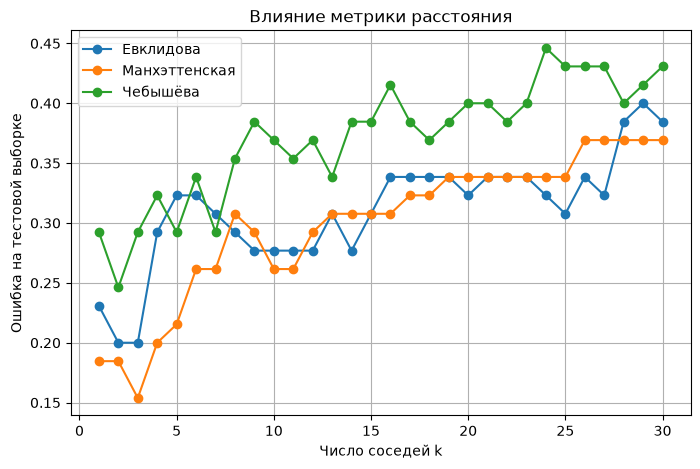

In [118]:
metrics = {'Евклидова': 'euclidean', 'Манхэттенская': 'manhattan', 'Чебышёва': 'chebyshev'}

plt.figure(figsize=(8, 5))
for name, metric in metrics.items():
    errs = []
    for k in ks:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric).fit(X3_train_s, y3_train)
        errs.append(1 - knn.score(X3_test_s, y3_test))
    plt.plot(ks, errs, marker='o', label=name)

plt.xlabel('Число соседей k')
plt.ylabel('Ошибка на тестовой выборке')
plt.title('Влияние метрики расстояния')
plt.legend()
plt.grid(True)
plt.show()

In [119]:
sample = pd.DataFrame([[1.516, 11.7, 1.01, 1.19, 72.59, 0.43, 11.44, 0.02, 0.1]],
                      columns=X3.columns)
knn = KNeighborsClassifier(n_neighbors=3).fit(X3_train_s, y3_train)
print('Тип стекла:', knn.predict(scaler.transform(sample))[0])

Тип стекла: 5


In [120]:
from sklearn.svm import SVC

def load_svm(path):
    df = pd.read_csv(path, sep=r'\s+')
    color = 'Color' if 'Color' in df.columns else 'Colors'
    X = df[['X1', 'X2']].values
    y = (df[color] == 'green').astype(int).values   # green = 1, red = 0
    return X, y

def plot_svm(model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.25, cmap='RdYlGn')
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c='red', edgecolor='k', label='red')
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c='green', edgecolor='k', label='green')
    sv = model.support_vectors_
    plt.scatter(sv[:, 0], sv[:, 1], s=140, facecolor='none', edgecolor='black', label='опорные векторы')
    plt.title(title)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend(fontsize=8)

Опорных векторов (red, green): [3 3]
Матрица ошибок train:
 [[20  0]
 [ 0 20]]
Матрица ошибок test:
 [[20  0]
 [ 0 20]]


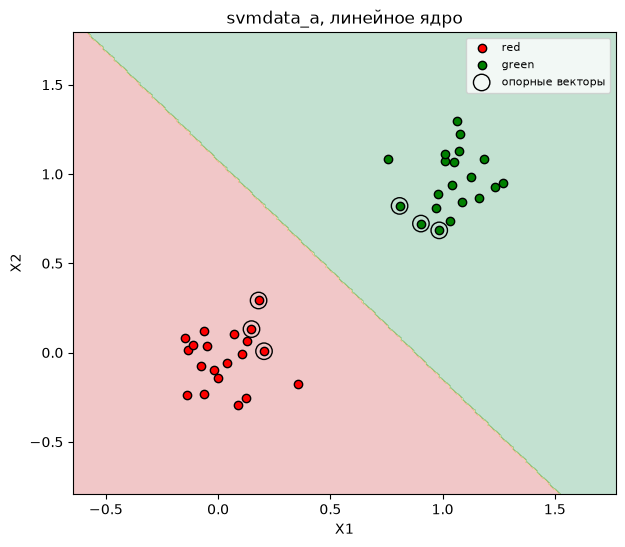

In [121]:
Xa, ya = load_svm('svmdata_a.txt')
Xa_te, ya_te = load_svm('svmdata_a_test.txt')

svm_a = SVC(kernel='linear', C=1).fit(Xa, ya)

print('Опорных векторов (red, green):', svm_a.n_support_)
print('Матрица ошибок train:\n', confusion_matrix(ya, svm_a.predict(Xa)))
print('Матрица ошибок test:\n', confusion_matrix(ya_te, svm_a.predict(Xa_te)))

plt.figure(figsize=(7, 6))
plot_svm(svm_a, Xa, ya, 'svmdata_a, линейное ядро')
plt.show()

In [122]:
Xb, yb = load_svm('svmdata_b.txt')
Xb_te, yb_te = load_svm('svmdata_b_test.txt')

rows = []
for C in [0.01, 0.1, 1, 10, 100, 500, 1000]:
    m = SVC(kernel='linear', C=C).fit(Xb, yb)
    rows.append({'C': C,
                 'ошибок train': (m.predict(Xb) != yb).sum(),
                 'ошибок test': (m.predict(Xb_te) != yb_te).sum(),
                 'опорных векторов': len(m.support_vectors_)})
pd.DataFrame(rows)

,C,ошибок train,ошибок test,опорных векторов
0,0.01,1,0,50
1,0.10,1,0,28
2,1.00,1,0,11
3,10.00,1,0,4
4,100.00,1,0,4
5,500.00,0,3,3
6,1000.00,0,3,3


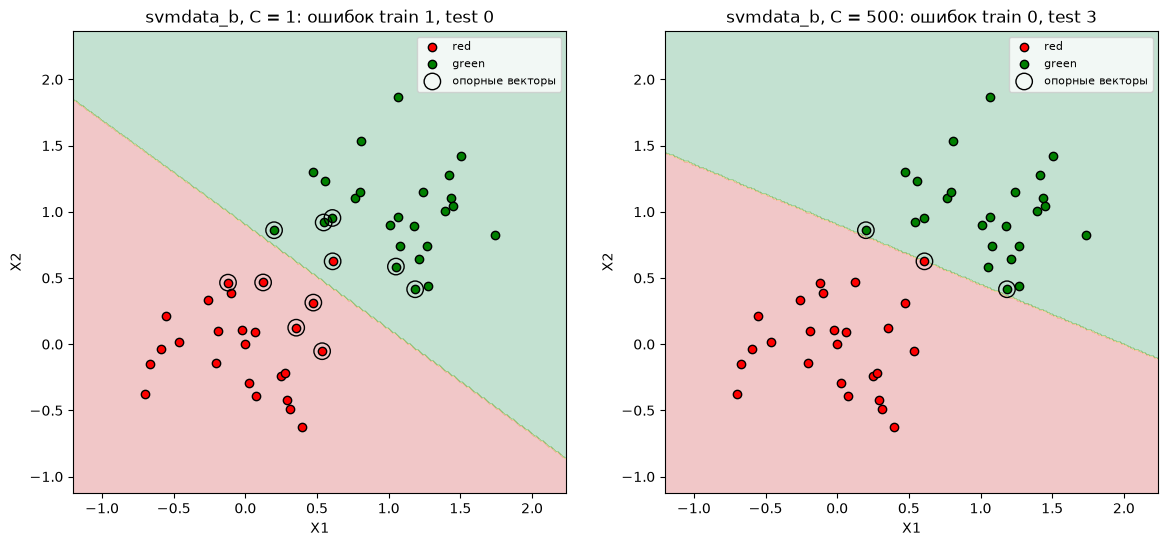

In [123]:
plt.figure(figsize=(14, 6))
for i, C in enumerate([1, 500]):
    m = SVC(kernel='linear', C=C).fit(Xb, yb)
    plt.subplot(1, 2, i + 1)
    plot_svm(m, Xb, yb, f'svmdata_b, C = {C}: ошибок train {(m.predict(Xb) != yb).sum()}, test {(m.predict(Xb_te) != yb_te).sum()}')
plt.show()

In [124]:
kernels = {'линейное': dict(kernel='linear'),
           'полином d=1': dict(kernel='poly', degree=1, coef0=1),
           'полином d=2': dict(kernel='poly', degree=2, coef0=1),
           'полином d=3': dict(kernel='poly', degree=3, coef0=1),
           'полином d=4': dict(kernel='poly', degree=4, coef0=1),
           'полином d=5': dict(kernel='poly', degree=5, coef0=1),
           'сигмоида': dict(kernel='sigmoid'),
           'гауссово (rbf)': dict(kernel='rbf')}

def compare_kernels(name, kernels):
    X, y = load_svm(f'svmdata_{name}.txt')
    X_te, y_te = load_svm(f'svmdata_{name}_test.txt')
    plt.figure(figsize=(18, 8))
    for i, (kname, params) in enumerate(kernels.items()):
        m = SVC(**params).fit(X, y)
        plt.subplot(2, 4, i + 1)
        plot_svm(m, X, y, f'{kname}: train {m.score(X, y):.2f}, test {m.score(X_te, y_te):.2f}')
    plt.tight_layout()
    plt.show()

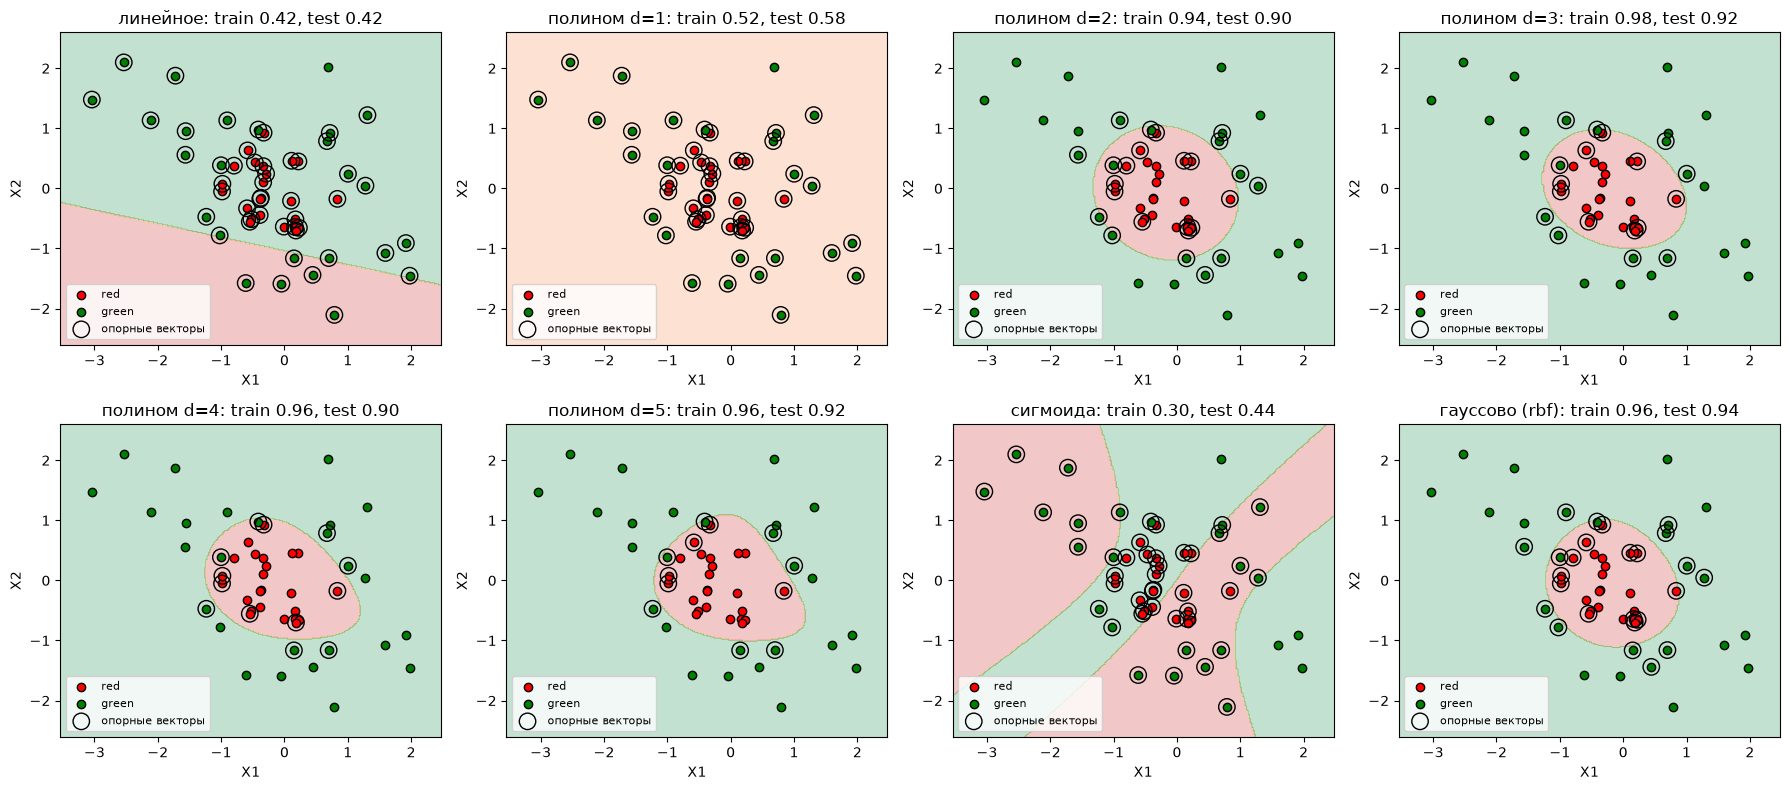

In [125]:
compare_kernels('c', kernels)

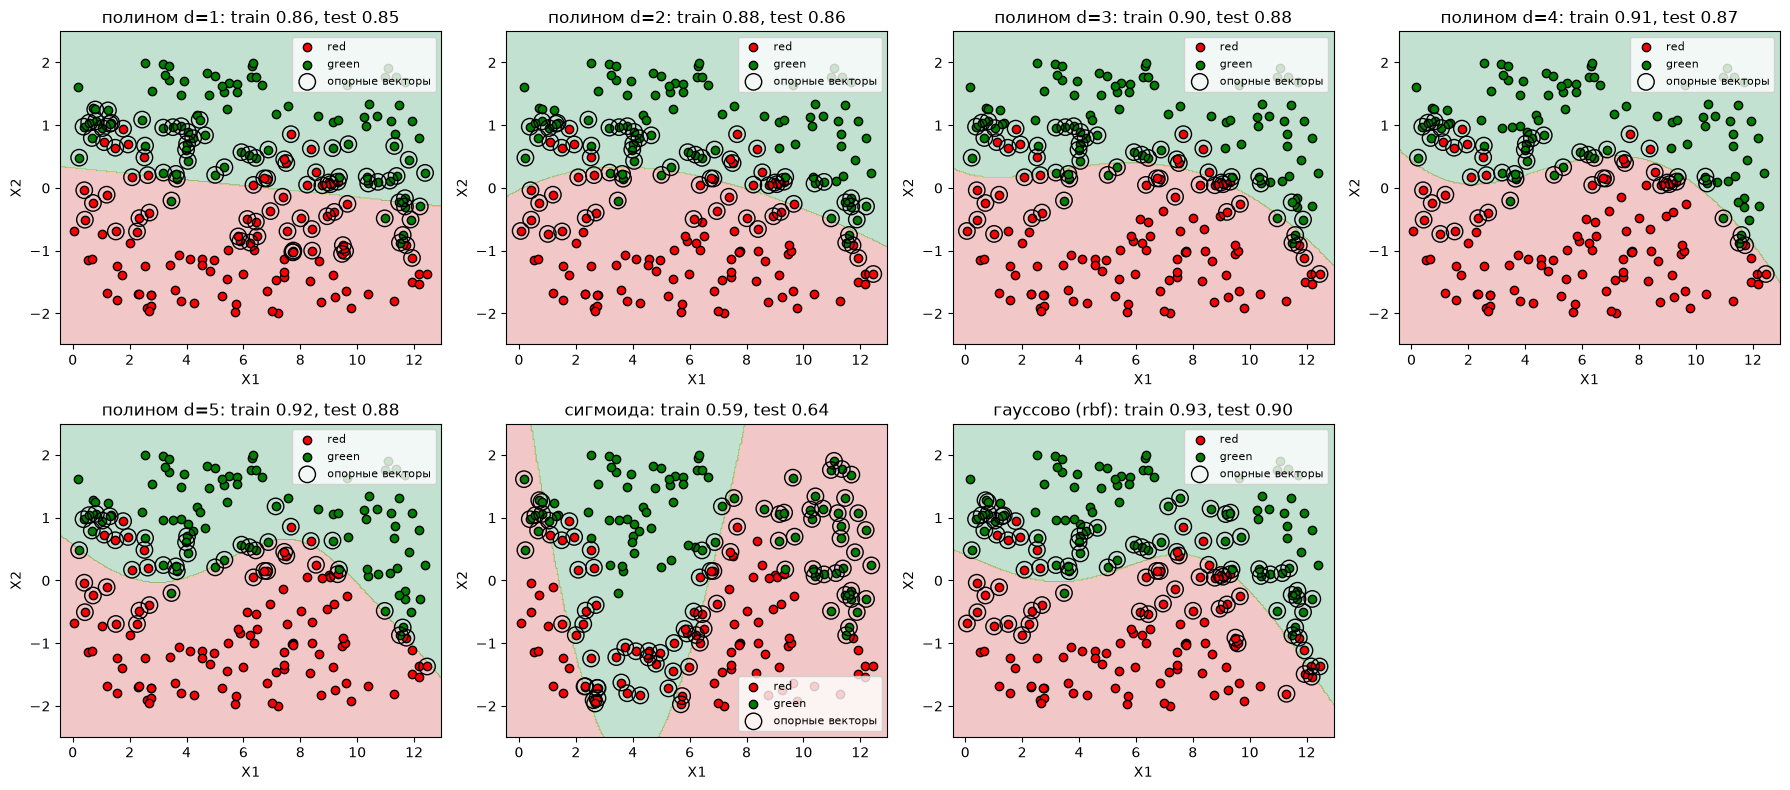

In [126]:
kernels_no_linear = {k: v for k, v in kernels.items() if k != 'линейное'}
compare_kernels('d', kernels_no_linear)

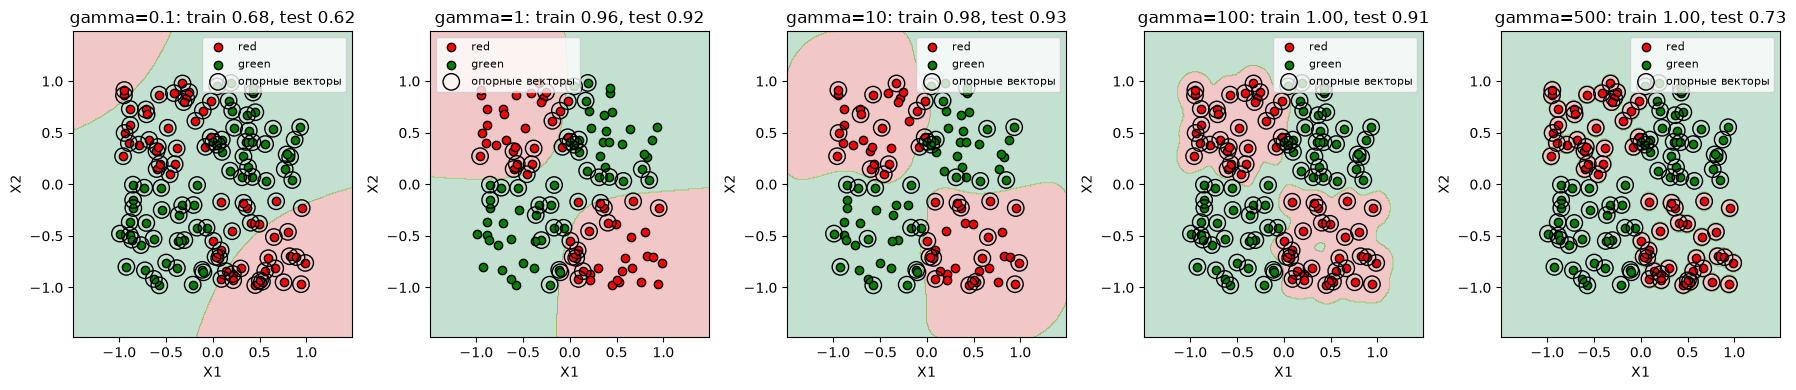

In [127]:
Xe, ye = load_svm('svmdata_e.txt')
Xe_te, ye_te = load_svm('svmdata_e_test.txt')

plt.figure(figsize=(18, 4))
for i, g in enumerate([0.1, 1, 10, 100, 500]):
    m = SVC(kernel='rbf', gamma=g).fit(Xe, ye)
    plt.subplot(1, 5, i + 1)
    plot_svm(m, Xe, ye, f'gamma={g}: train {m.score(Xe, ye):.2f}, test {m.score(Xe_te, ye_te):.2f}')
plt.tight_layout()
plt.show()

### Выводы по заданию 4c–4e
1. svmdata_c (красные точки внутри круга): линейное ядро и полином степени 1 не справляются (test 0.42 и 0.58), прямая не может окружить круг. Полиномы степени 2–5 и гауссово ядро дают 0.90–0.94, лучшее — гауссово (0.94). Сигмоида работает хуже угадывания.
2. svmdata_d (граница-волна): с ростом степени полинома точность растёт, лучшее — гауссово ядро (0.90).
3. svmdata_e (классы в шахматном порядке): полином степени 1 даёт 0.65, полиномы степени 2–5 — 0.93–0.95, гауссово — 0.92.
4. Параметр gamma: при малом значении граница слишком гладкая (test 0.62 — недообучение), при gamma = 1–10 результат лучший (0.92–0.93), при gamma = 500 точность на обучающей выборке 1.00, а на тестовой падает до 0.73 — переобучение: вокруг каждой точки образуется отдельная область.

## Задание 5. Деревья решений 
## 5a. Glass

Глубина: 11  листьев: 38
accuracy train: 1.0  test: 0.738


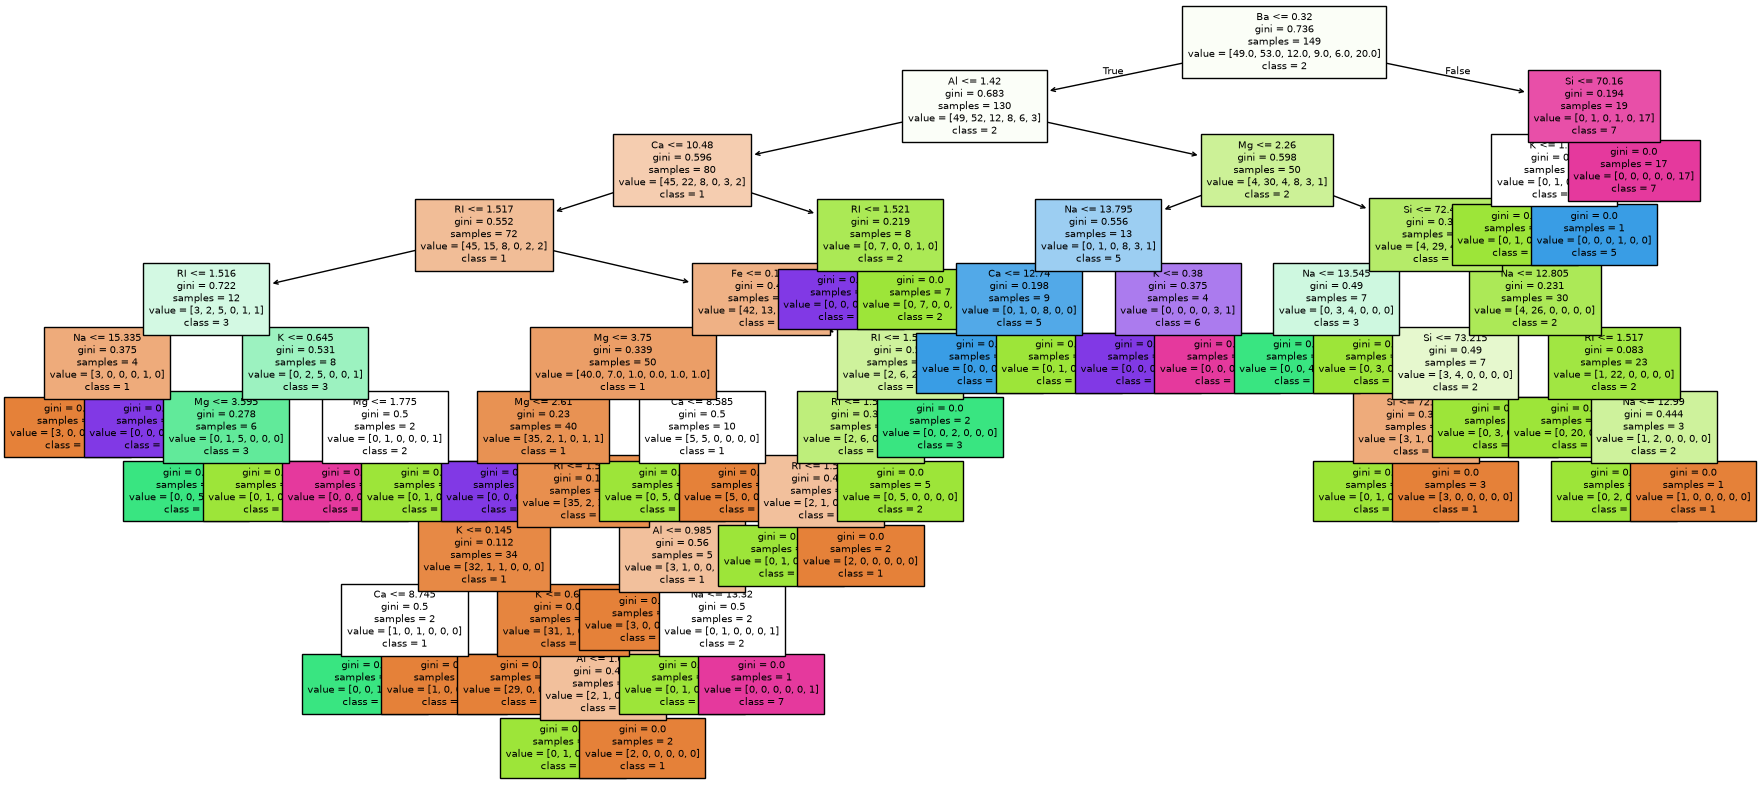

In [128]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(random_state=42).fit(X3_train, y3_train)
print('Глубина:', tree.get_depth(), ' листьев:', tree.get_n_leaves())
print('accuracy train:', tree.score(X3_train, y3_train), ' test:', round(tree.score(X3_test, y3_test), 3))

plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=list(X3.columns), class_names=[str(c) for c in tree.classes_],
          filled=True, fontsize=7)
plt.show()

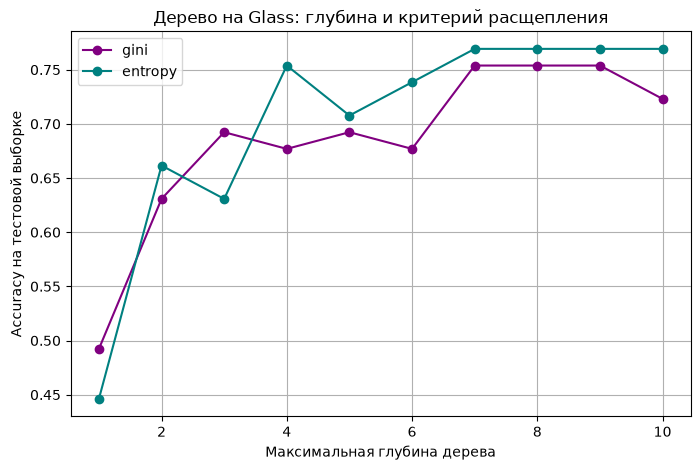

In [129]:
depths = range(1, 11)
plt.figure(figsize=(8, 5))
for crit, color in [('gini', 'purple'), ('entropy', 'teal')]:
    acc = [DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=42)
           .fit(X3_train, y3_train).score(X3_test, y3_test) for d in depths]
    plt.plot(depths, acc, marker='o', color=color, label=crit)
plt.xlabel('Максимальная глубина дерева')
plt.ylabel('Accuracy на тестовой выборке')
plt.title('Дерево на Glass: глубина и критерий расщепления')
plt.legend()
plt.grid(True)
plt.show()

### Выводы по заданию 5a
1. Полное дерево имеет глубину 11 и 38 листьев; на обучающей выборке точность 1.0, на тестовой 0.738 — дерево избыточно и переобучено: оно запоминает отдельные объекты.
2. При глубине 1 точность низкая (~0.45–0.49): один вопрос делит данные на две группы, а классов шесть. С ростом глубины точность растёт и после глубины 7–8 перестаёт улучшаться (~0.75–0.77).
3. Критерии gini и entropy дают близкие результаты: оба измеряют, насколько перемешаны классы в узле.
4. Первым вопросом дерево проверяет содержание Ba: барий характерен для стекла фар (тип 7).

### 5b. Spam7

Лучшие параметры: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 20}
accuracy CV: 0.873  test: 0.865
[[777  60]
 [126 418]]


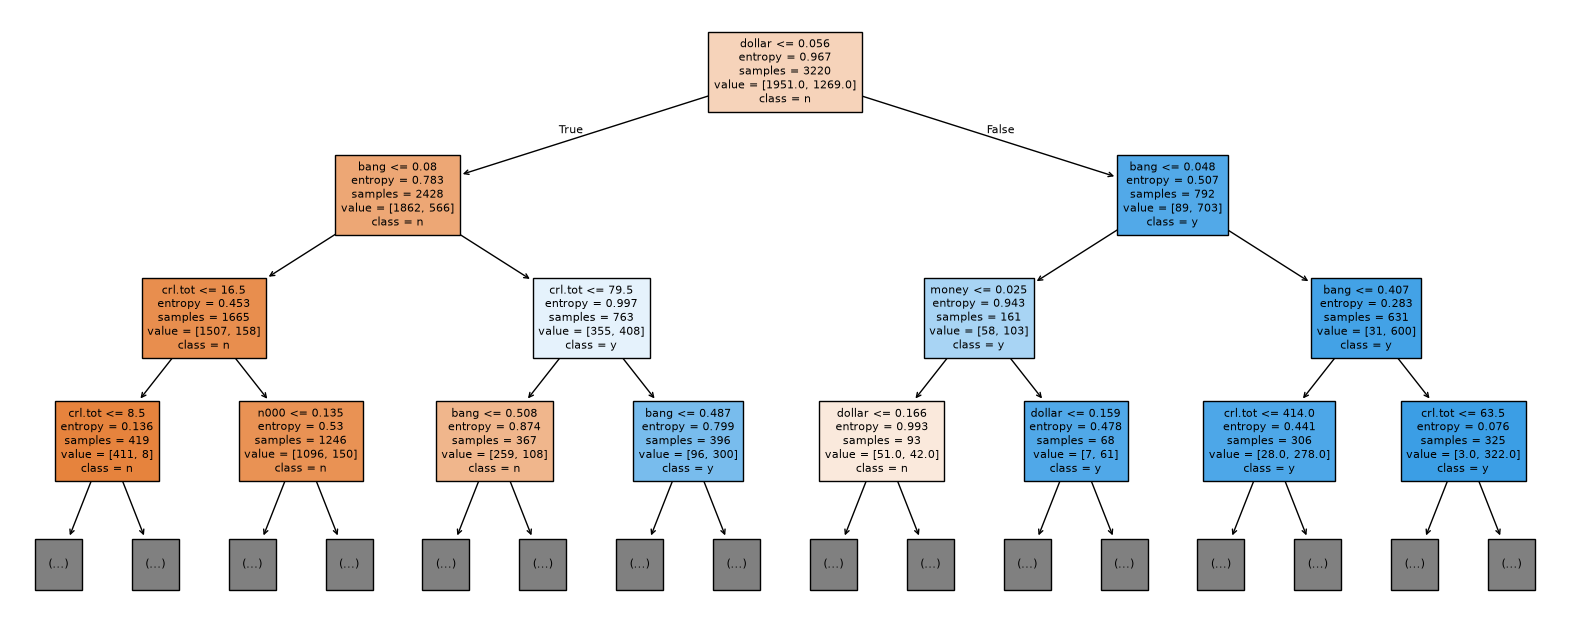

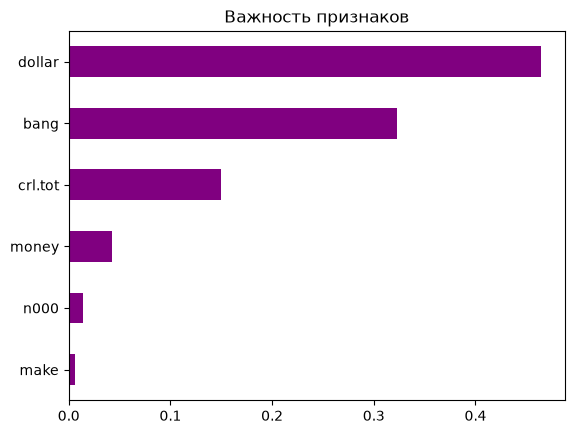

In [131]:
from sklearn.model_selection import GridSearchCV

spam7 = pd.read_csv('spam7.csv')
X5 = spam7.drop(columns='yesno')
y5 = spam7['yesno']
X5_train, X5_test, y5_train, y5_test = train_test_split(X5, y5, test_size=0.3, random_state=42, stratify=y5)

params = {'criterion': ['gini', 'entropy'],
          'max_depth': [3, 4, 5, 6, 8, 10],
          'min_samples_leaf': [1, 5, 10, 20]}
gs = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=5).fit(X5_train, y5_train)
best = gs.best_estimator_

print('Лучшие параметры:', gs.best_params_)
print('accuracy CV:', round(gs.best_score_, 3), ' test:', round(best.score(X5_test, y5_test), 3))
print(confusion_matrix(y5_test, best.predict(X5_test)))

plt.figure(figsize=(20, 8))
plot_tree(best, feature_names=list(X5.columns), class_names=list(best.classes_),
          filled=True, max_depth=3, fontsize=8)
plt.show()

pd.Series(best.feature_importances_, index=X5.columns).sort_values().plot(kind='barh', color='purple')
plt.title('Важность признаков')
plt.show()

### Выводы по заданию 5b
1. Параметры подобраны перебором GridSearchCV (48 комбинаций критерия, максимальной глубины и минимального размера листа) с 5-кратной кросс-валидацией на обучающей выборке. Лучшие: entropy, глубина 8, минимум 20 объектов в листе.
2. Accuracy: на кросс-валидации 0.873, на тестовой выборке 0.865.
3. Наиболее важные признаки: dollar (частота символа $), bang (частота !) и crl.tot (общая длина последовательностей заглавных букв) — типичные признаки рекламного спама.

## Задание 6. Система выдачи кредита (bank_scoring)

train: (96216, 10)  test: (24053, 10)
Доля «плохих» клиентов: 0.069


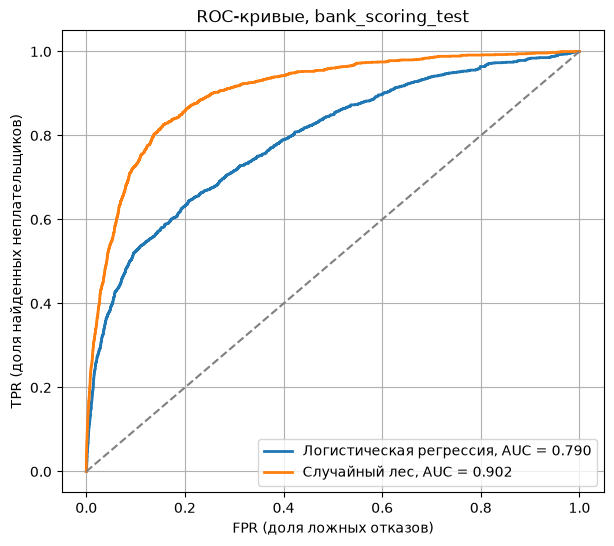

,система,ROC AUC,recall,precision,accuracy
0,Логистическая регрессия,0.790,0.626,0.192,0.794
1,Случайный лес,0.902,0.808,0.292,0.853


In [132]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, recall_score, precision_score

train6 = pd.read_csv('bank_scoring_train.csv', sep='\t')
test6 = pd.read_csv('bank_scoring_test.csv', sep='\t')
X6_train = train6.drop(columns='SeriousDlqin2yrs')
y6_train = train6['SeriousDlqin2yrs']
X6_test = test6.drop(columns='SeriousDlqin2yrs')
y6_test = test6['SeriousDlqin2yrs']
print('train:', X6_train.shape, ' test:', X6_test.shape)
print('Доля «плохих» клиентов:', round(y6_train.mean(), 3))

models = {'Логистическая регрессия': make_pipeline(StandardScaler(),
                LogisticRegression(class_weight='balanced', max_iter=1000)),
          'Случайный лес': RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                class_weight='balanced', random_state=42, n_jobs=-1)}

rows = []
plt.figure(figsize=(7, 6))
for name, m in models.items():
    m.fit(X6_train, y6_train)
    proba = m.predict_proba(X6_test)[:, 1]
    pred = m.predict(X6_test)
    rows.append({'система': name,
                 'ROC AUC': roc_auc_score(y6_test, proba),
                 'recall': recall_score(y6_test, pred),
                 'precision': precision_score(y6_test, pred),
                 'accuracy': accuracy_score(y6_test, pred)})
    fpr, tpr, _ = roc_curve(y6_test, proba)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name}, AUC = {roc_auc_score(y6_test, proba):.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('FPR (доля ложных отказов)')
plt.ylabel('TPR (доля найденных неплательщиков)')
plt.title('ROC-кривые, bank_scoring_test')
plt.legend()
plt.grid(True)
plt.show()

pd.DataFrame(rows).round(3)

### Выводы по заданию 6
1. Классы сильно несбалансированы: неплательщиков около 7 %. Поэтому accuracy не подходит — модель «выдать всем» уже даёт 0.93, но не находит ни одного неплательщика. Основная метрика — ROC AUC (насколько хорошо модель ранжирует клиентов по риску); дополнительно recall — какую долю будущих неплательщиков система отсеет.
2. Сравнивались две системы: логистическая регрессия и случайный лес, обе с class_weight='balanced'.
3. На bank_scoring_test.csv случайный лес лучше: ROC AUC 0.902 против 0.790, recall 0.81 против 0.63.
4. Лучшая система — случайный лес: зависимость риска от признаков нелинейная, а лес учитывает это и усредняет много деревьев.